In [1]:
import pandas as pd
import numpy as np

# Load the datasets
train = pd.read_csv(r"C:\Users\USER\Documents\BISMILLAH\Python\perf_train.csv",index_col=0 )
test = pd.read_csv(r"C:\Users\USER\Documents\BISMILLAH\Python\perf_test.csv",index_col=0)

print("Training shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())

Training shape: (2000, 21)
Test shape: (500, 20)


,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
Employee_ID,,,,,,,,,,,,,,,,,,,,,
10001,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,1.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,0.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
10003,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,1.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,5.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
10005,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,0.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer


In [2]:
print("TRAINING DATA INFORMATION")
train.info()

print("\nMISSING VALUES IN TRAINING DATA")
print(train.isnull().sum().sort_values(ascending=False))

print("\nMISSING VALUES IN TEST DATA")
print(test.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE TRAINING ROWS:", train.duplicated().sum())
print("DUPLICATE EMPLOYEE IDs:", train["Employee_ID"].duplicated().sum())

TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 10001 to 12000
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   1873 non-null   float64
 1   Gender                1934 non-null   object 
 2   City                  1789 non-null   object 
 3   Education_Level       1806 non-null   object 
 4   Department            1801 non-null   object 
 5   Experience_Years      1747 non-null   float64
 6   Monthly_Salary        1895 non-null   float64
 7   Projects_Completed    1712 non-null   float64
 8   Training_Hours        1702 non-null   float64
 9   Certifications        1695 non-null   float64
 10  Work_Life_Balance     1819 non-null   float64
 11  Job_Satisfaction      1804 non-null   float64
 12  Manager_Rating        1853 non-null   float64
 13  Overtime_Hours        1810 non-null   float64
 14  Commute_Time_Min      1805 non-null   float64


KeyError: 'Employee_ID'

In [4]:
print(train["Performance_Category"].value_counts())

print("\nClass proportions:")
print(
    train["Performance_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64

Class proportions:
Performance_Category
Average Performer    56.45
Low Performer        33.15
High Performer       10.40
Name: proportion, dtype: float64


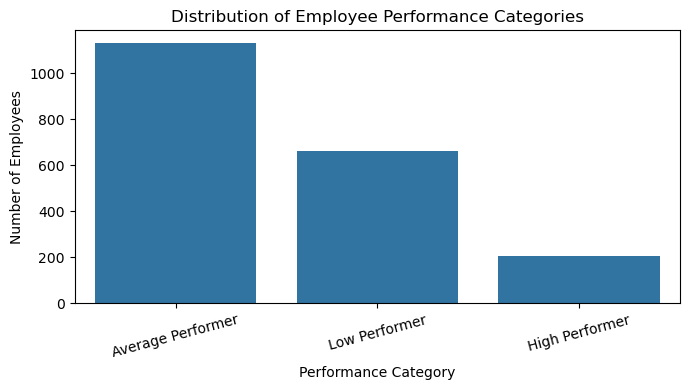

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=train,
    x="Performance_Category",
    order=train["Performance_Category"].value_counts().index
)

plt.title("Distribution of Employee Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [6]:
# Missing values in training data
missing = train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(train) * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

# Check data types
print("\nColumn data types:")
print(train.dtypes)

,Missing_Count,Missing_Percentage
Internet_Stability,343,17.15
Absenteeism_Days,319,15.95
Certifications,305,15.25
Training_Hours,298,14.90
Projects_Completed,288,14.40
Cafeteria_Rating,283,14.15
Experience_Years,253,12.65
City,211,10.55
Department,199,9.95
Job_Satisfaction,196,9.80



Column data types:
Age                     float64
Gender                   object
City                     object
Education_Level          object
Department               object
Experience_Years        float64
Monthly_Salary          float64
Projects_Completed      float64
Training_Hours          float64
Certifications          float64
Work_Life_Balance       float64
Job_Satisfaction        float64
Manager_Rating          float64
Overtime_Hours          float64
Commute_Time_Min        float64
Laptop_Issue_Count      float64
Cafeteria_Rating        float64
Internet_Stability       object
Last_Promotion_Years    float64
Absenteeism_Days        float64
Performance_Category     object
dtype: object


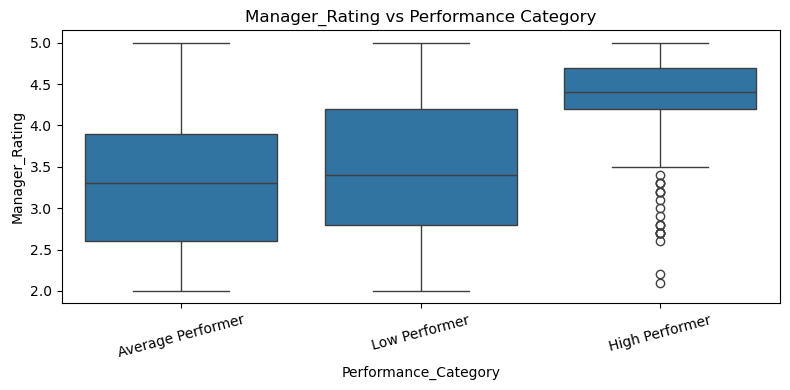

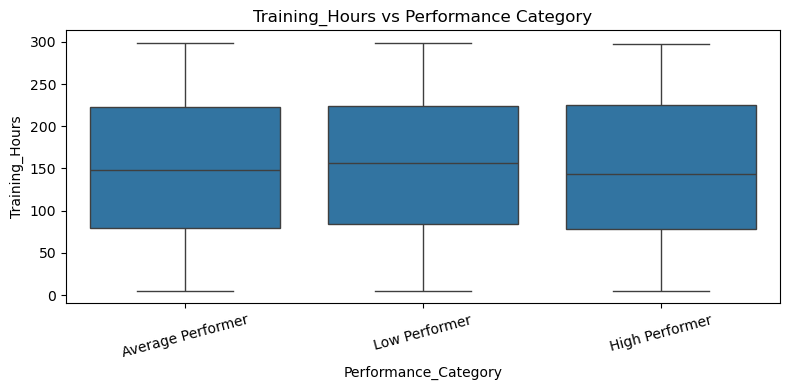

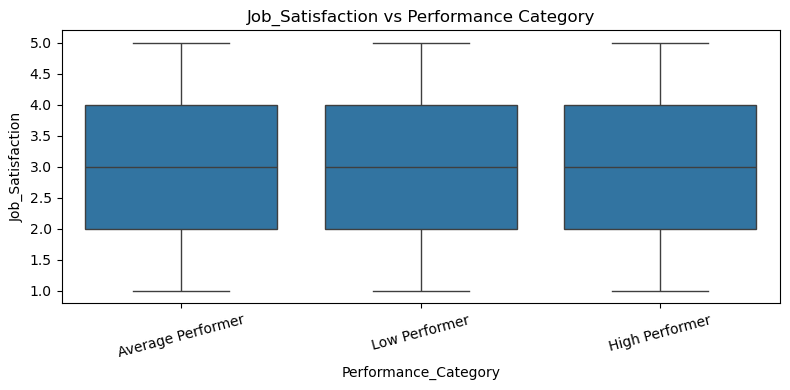

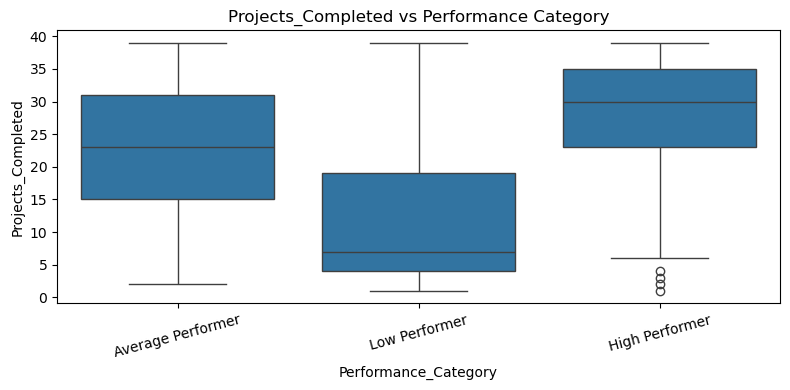

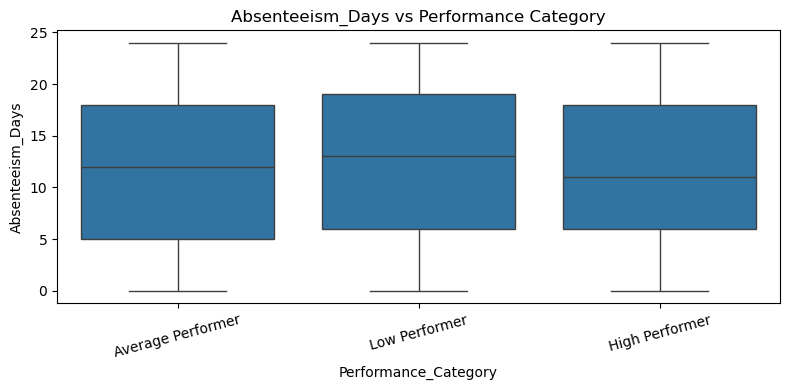

In [8]:
important_features = [
    "Manager_Rating",
    "Training_Hours",
    "Job_Satisfaction",
    "Projects_Completed",
    "Absenteeism_Days"
]

for feature in important_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=train,
        x="Performance_Category",
        y=feature
    )

    plt.title(f"{feature} vs Performance Category")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [9]:
categorical_columns = train.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_columns:
    print(f"\n{col}")
    print(train[col].value_counts(dropna=False).head(15))


Gender
Gender
Male      1048
Female     845
NaN         66
Other       41
Name: count, dtype: int64

City
City
Delhi        294
Kolkata      268
Chennai      265
Pune         254
Mumbai       245
Hyderabad    241
Bengaluru    222
NaN          211
Name: count, dtype: int64

Education_Level
Education_Level
Graduate         841
Post Graduate    703
NaN              194
Diploma          178
PhD               84
Name: count, dtype: int64

Department
Department
Sales         323
Operations    305
Analytics     304
Finance       304
IT            284
HR            281
NaN           199
Name: count, dtype: int64

Internet_Stability
Internet_Stability
Average      444
Good         436
Poor         402
Excellent    375
NaN          343
Name: count, dtype: int64

Performance_Category
Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64


In [10]:
%pip install -q scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [11]:
from sklearn.model_selection import train_test_split

# Target variable
y = train["Performance_Category"]

# Remove target and unique ID from predictive features
X = train.drop(
    columns=["Performance_Category", "Employee_ID"]
)

# Keep the same feature columns for the test dataset
X_test = test.drop(columns=["Employee_ID"])

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Training features shape:", X.shape)
print("Test features shape:", X_test.shape)

KeyError: "['Employee_ID'] not found in axis"

In [12]:
print("Train columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nTraining index name:", train.index.name)
print("Test index name:", test.index.name)

Train columns:
['Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days', 'Performance_Category']

Test columns:
['Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days']

Training index name: Employee_ID
Test index name: Employee_ID


In [13]:
if train.index.name == "Employee_ID":
    train = train.reset_index()

if test.index.name == "Employee_ID":
    test = test.reset_index()

In [14]:
from sklearn.model_selection import train_test_split

# Target variable
y = train["Performance_Category"]

# Keep employee IDs separately for final submission
train_ids = train["Employee_ID"].copy()
test_ids = test["Employee_ID"].copy()

# Remove target and ID from predictive features
X = train.drop(columns=["Performance_Category", "Employee_ID"])
X_test = test.drop(columns=["Employee_ID"])

# Identify column types
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Training features shape:", X.shape)
print("Test features shape:", X_test.shape)

Numerical features: 15
Categorical features: 5
Training features shape: (2000, 20)
Test features shape: (500, 20)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_valid.value_counts())

Training rows: 1600
Validation rows: 400

Training class distribution:
Performance_Category
Average Performer    903
Low Performer        530
High Performer       167
Name: count, dtype: int64

Validation class distribution:
Performance_Category
Average Performer    226
Low Performer        133
High Performer        41
Name: count, dtype: int64


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

# Handle numerical columns
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Handle categorical columns
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Create the model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Predict validation data
valid_predictions = baseline_model.predict(X_valid)

# Evaluate accuracy
accuracy = accuracy_score(y_valid, valid_predictions)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_valid, valid_predictions, zero_division=0))

Validation Accuracy: 0.8125
Validation Accuracy: 81.25%

Classification Report:
                   precision    recall  f1-score   support

Average Performer       0.78      0.95      0.86       226
   High Performer       0.71      0.12      0.21        41
    Low Performer       0.89      0.79      0.84       133

         accuracy                           0.81       400
        macro avg       0.80      0.62      0.63       400
     weighted avg       0.81      0.81      0.78       400



In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict the validation data using your existing trained model
y_pred = model.predict(X_val)

# Display confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=["Average Performer", "High Performer", "Low Performer"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Average", "High", "Low"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Employee Performance - Confusion Matrix")
plt.show()


NameError: name 'model' is not defined

In [18]:

%whos


Variable                  Type                 Data/Info
--------------------------------------------------------
ColumnTransformer         ABCMeta              <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay    type                 <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
ExtraTreesClassifier      ABCMeta              <class 'sklearn.ensemble.<...>st.ExtraTreesClassifier'>
OneHotEncoder             type                 <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                  ABCMeta              <class 'sklearn.pipeline.Pipeline'>
SimpleImputer             type                 <class 'sklearn.impute._base.SimpleImputer'>
X                         DataFrame                   Age  Gender       <...>n[2000 rows x 20 columns]
X_test                    DataFrame                  Age  Gender       C<...>\n[500 rows x 20 columns]
X_train                   DataFrame                   Age  Gender       <...>n[1600 rows x 20

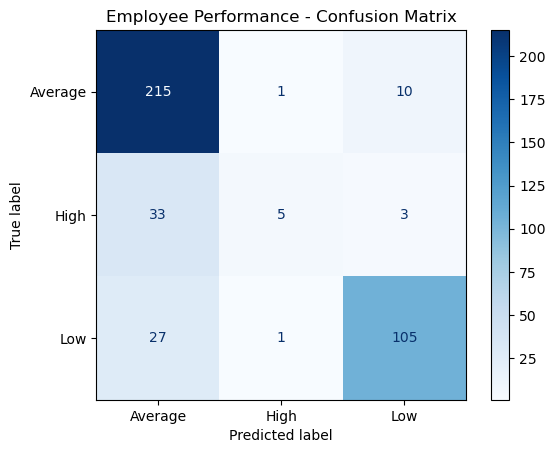

In [19]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using your trained model
y_pred = baseline_model.predict(X_valid)

# Create confusion matrix
cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=[
        "Average Performer",
        "High Performer",
        "Low Performer"
    ]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Average", "High", "Low"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Employee Performance - Confusion Matrix")
plt.show()


In [20]:

print("Training category counts:")
print(y_train.value_counts())

print("\nTraining category percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))


Training category counts:
Performance_Category
Average Performer    903
Low Performer        530
High Performer       167
Name: count, dtype: int64

Training category percentages:
Performance_Category
Average Performer    56.44
Low Performer        33.12
High Performer       10.44
Name: proportion, dtype: float64


In [21]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create a new model using your existing preprocessor
balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the balanced model
balanced_model.fit(X_train, y_train)

# Predict validation categories
y_pred_balanced = balanced_model.predict(X_valid)

# Evaluate the new model
print("Balanced Model Accuracy:",
      round(accuracy_score(y_valid, y_pred_balanced), 4))

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_balanced))


Balanced Model Accuracy: 0.79

Classification Report:
                   precision    recall  f1-score   support

Average Performer       0.74      0.98      0.85       226
   High Performer       0.00      0.00      0.00        41
    Low Performer       0.92      0.71      0.81       133

         accuracy                           0.79       400
        macro avg       0.56      0.56      0.55       400
     weighted avg       0.73      0.79      0.75       400



C:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [22]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

custom_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=300,
        class_weight={
            "Average Performer": 1.0,
            "High Performer": 4.0,
            "Low Performer": 1.0
        },
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
custom_model.fit(X_train, y_train)

# Predict validation data
y_pred_custom = custom_model.predict(X_valid)

# Evaluate
print("Custom Model Accuracy:",
      round(accuracy_score(y_valid, y_pred_custom), 4))

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_custom, zero_division=0))


Custom Model Accuracy: 0.79

Classification Report:
                   precision    recall  f1-score   support

Average Performer       0.74      0.98      0.84       226
   High Performer       0.00      0.00      0.00        41
    Low Performer       0.94      0.71      0.81       133

         accuracy                           0.79       400
        macro avg       0.56      0.56      0.55       400
     weighted avg       0.73      0.79      0.75       400



In [23]:

print("Actual validation category counts:")
print(y_valid.value_counts())

print("\nBaseline model predictions:")
print(baseline_model.predict(X_valid).__class__)
print(
    __import__("pandas").Series(
        baseline_model.predict(X_valid)
    ).value_counts()
)

print("\nCustom model predictions:")
print(
    __import__("pandas").Series(
        custom_model.predict(X_valid)
    ).value_counts()
)


Actual validation category counts:
Performance_Category
Average Performer    226
Low Performer        133
High Performer        41
Name: count, dtype: int64

Baseline model predictions:
<class 'numpy.ndarray'>
Average Performer    275
Low Performer        118
High Performer         7
Name: count, dtype: int64

Custom model predictions:
Average Performer    300
Low Performer        100
Name: count, dtype: int64


In [24]:

import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Get predicted probabilities
probabilities = baseline_model.predict_proba(X_valid)

# Find the High Performer column
classes = baseline_model.classes_
high_index = list(classes).index("High Performer")

print("Model classes:", classes)
print("\nFirst 10 High Performer probabilities:")
print(np.round(probabilities[:10, high_index], 3))

# Test different thresholds
for threshold in [0.10, 0.15, 0.20, 0.25, 0.30]:
    predictions = baseline_model.predict(X_valid)

    # Assign High Performer when its probability meets the threshold
    high_mask = probabilities[:, high_index] >= threshold
    predictions[high_mask] = "High Performer"

    print(f"\n--- Threshold: {threshold} ---")
    print("Accuracy:", round(accuracy_score(y_valid, predictions), 4))
    print(classification_report(
        y_valid,
        predictions,
        labels=["Average Performer", "High Performer", "Low Performer"],
        zero_division=0
    ))


Model classes: ['Average Performer' 'High Performer' 'Low Performer']

First 10 High Performer probabilities:
[0.307 0.109 0.171 0.096 0.191 0.386 0.073 0.201 0.111 0.216]

--- Threshold: 0.1 ---
Accuracy: 0.38
                   precision    recall  f1-score   support

Average Performer       0.83      0.23      0.36       226
   High Performer       0.14      0.88      0.24        41
    Low Performer       0.88      0.48      0.62       133

         accuracy                           0.38       400
        macro avg       0.61      0.53      0.41       400
     weighted avg       0.77      0.38      0.43       400


--- Threshold: 0.15 ---
Accuracy: 0.575
                   precision    recall  f1-score   support

Average Performer       0.87      0.48      0.62       226
   High Performer       0.19      0.83      0.31        41
    Low Performer       0.90      0.66      0.76       133

         accuracy                           0.57       400
        macro avg       0.65      0

In [25]:

import numpy as np

def predict_employee_performance(model, X, threshold=0.30):
    probabilities = model.predict_proba(X)
    classes = list(model.classes_)

    high_index = classes.index("High Performer")

    # Start with the model's normal predictions
    predictions = model.predict(X)

    # Override with High Performer when probability meets threshold
    high_mask = probabilities[:, high_index] >= threshold
    predictions[high_mask] = "High Performer"

    return predictions

# Check the selected threshold on validation data
final_valid_predictions = predict_employee_performance(
    baseline_model, X_valid, threshold=0.30
)

print(classification_report(
    y_valid,
    final_valid_predictions,
    zero_division=0
))


                   precision    recall  f1-score   support

Average Performer       0.82      0.91      0.86       226
   High Performer       0.53      0.41      0.47        41
    Low Performer       0.89      0.78      0.83       133

         accuracy                           0.81       400
        macro avg       0.75      0.70      0.72       400
     weighted avg       0.81      0.81      0.81       400



In [26]:

import joblib

model_artifact = {
    "model": baseline_model,
    "high_performer_threshold": 0.30
}

joblib.dump(
    model_artifact,
    "employee_performance_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [27]:

print("Test dataset shape:", test.shape)
print("\nTest dataset columns:")
print(test.columns.tolist())

print("\nTest feature shape:", X_test.shape)
print("\nFirst 5 employee IDs:")
print(test_ids.head())


Test dataset shape: (500, 21)

Test dataset columns:
['Employee_ID', 'Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days']

Test feature shape: (500, 20)

First 5 employee IDs:
0    12001
1    12002
2    12003
3    12004
4    12005
Name: Employee_ID, dtype: int64


In [28]:

# Predict performance categories for the 500 test employees
test_predictions = predict_employee_performance(
    baseline_model,
    X_test,
    threshold=0.30
)

print("Total predictions:", len(test_predictions))
print("\nPredicted category counts:")
print(pd.Series(test_predictions).value_counts())


Total predictions: 500

Predicted category counts:
Average Performer    332
Low Performer        121
High Performer        47
Name: count, dtype: int64


In [29]:

# Create a results DataFrame
predictions_df = pd.DataFrame({
    "Employee_ID": test_ids.values,
    "Predicted_Performance_Category": test_predictions
})

print(predictions_df.head())
print("\nPrediction file shape:", predictions_df.shape)


   Employee_ID Predicted_Performance_Category
0        12001              Average Performer
1        12002              Average Performer
2        12003              Average Performer
3        12004                  Low Performer
4        12005              Average Performer

Prediction file shape: (500, 2)


In [30]:

predictions_df.to_csv(
    "employee_performance_predictions.csv",
    index=False
)

print("Predictions exported successfully!")


Predictions exported successfully!


In [31]:

print("Test dataset shape:", test.shape)

print("\nTest dataset columns:")
print(test.columns.tolist())

print("\nTest feature shape:", X_test.shape)

print("\nFirst 5 employee IDs:")
print(test_ids.head())


Test dataset shape: (500, 21)

Test dataset columns:
['Employee_ID', 'Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days']

Test feature shape: (500, 20)

First 5 employee IDs:
0    12001
1    12002
2    12003
3    12004
4    12005
Name: Employee_ID, dtype: int64


In [32]:

test_predictions = predict_employee_performance(
    baseline_model,
    X_test,
    threshold=0.30
)

print("Total predictions:", len(test_predictions))

print("\nPredicted performance categories:")
print(pd.Series(test_predictions).value_counts())


Total predictions: 500

Predicted performance categories:
Average Performer    332
Low Performer        121
High Performer        47
Name: count, dtype: int64


In [33]:

predictions_df = pd.DataFrame({
    "Employee_ID": test_ids.values,
    "Predicted_Performance_Category": test_predictions
})

predictions_df.to_csv(
    "employee_performance_predictions.csv",
    index=False
)

print("Prediction file created successfully!")
print(predictions_df.head())
print("Total rows:", len(predictions_df))


Prediction file created successfully!
   Employee_ID Predicted_Performance_Category
0        12001              Average Performer
1        12002              Average Performer
2        12003              Average Performer
3        12004                  Low Performer
4        12005              Average Performer
Total rows: 500


In [34]:

predictions_df = pd.DataFrame({
    "Employee_ID": test_ids.values,
    "Predicted_Performance_Category": test_predictions
})

predictions_df.to_csv(
    "employee_performance_predictions.csv",
    index=False
)

print("File saved successfully!")
print(predictions_df.head())


File saved successfully!
   Employee_ID Predicted_Performance_Category
0        12001              Average Performer
1        12002              Average Performer
2        12003              Average Performer
3        12004                  Low Performer
4        12005              Average Performer


In [35]:

# Extract the trained preprocessing and classifier steps
fitted_preprocessor = baseline_model.named_steps["preprocessor"]
fitted_classifier = baseline_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 important features:")
print(importance_df.head(15).to_string(index=False))


Top 15 important features:
                  Feature  Importance
  num__Projects_Completed    0.156831
    num__Experience_Years    0.113208
      num__Manager_Rating    0.104132
   num__Work_Life_Balance    0.025601
  num__Laptop_Issue_Count    0.025582
    num__Cafeteria_Rating    0.025314
                 num__Age    0.025167
    num__Job_Satisfaction    0.024395
      num__Monthly_Salary    0.024386
    num__Absenteeism_Days    0.024137
    num__Commute_Time_Min    0.024034
      num__Overtime_Hours    0.023934
      num__Certifications    0.023618
num__Last_Promotion_Years    0.023405
      num__Training_Hours    0.022617


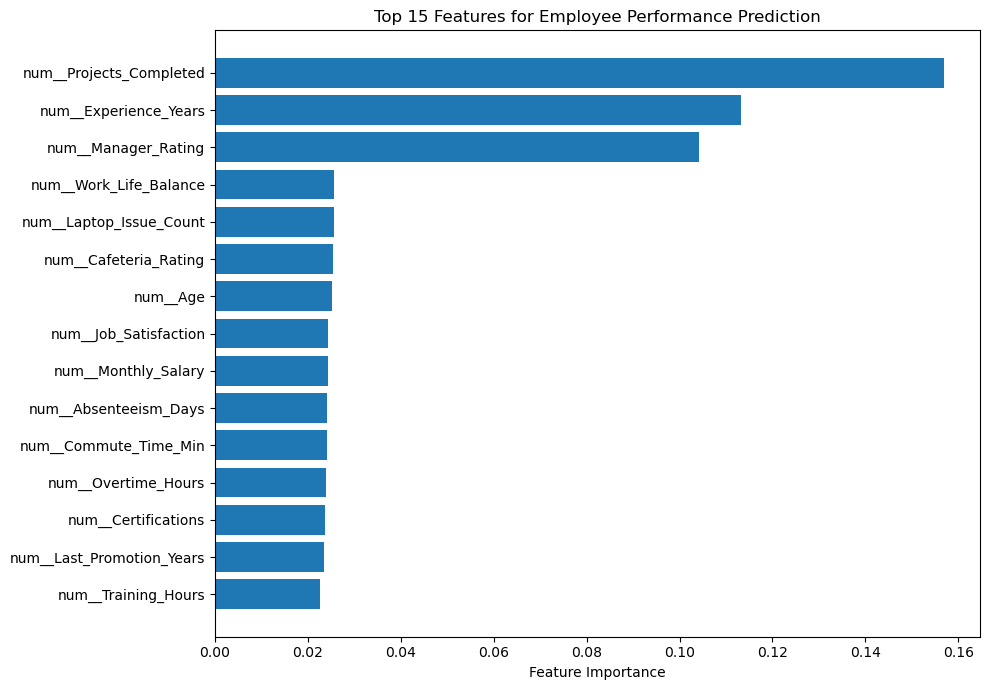

In [36]:

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features for Employee Performance Prediction")
plt.tight_layout()
plt.show()


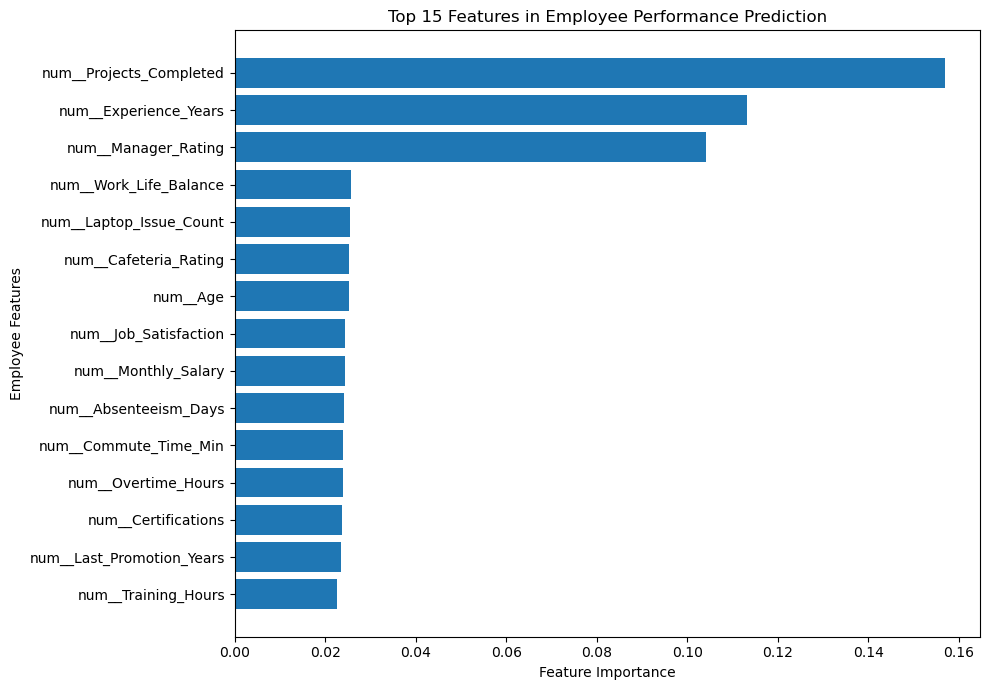

In [37]:

import matplotlib.pyplot as plt

top15 = importance_df.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top15["Feature"], top15["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Employee Features")
plt.title("Top 15 Features in Employee Performance Prediction")
plt.tight_layout()
plt.savefig("employee_feature_importance.png", dpi=300)
plt.show()


In [38]:

# Create the submission in the required format
submission = pd.DataFrame({
    "Employee_ID": test_ids.values,
    "Performance_Category": test_predictions
})

# Check the submission
print(submission.head(10))
print("\nSubmission shape:", submission.shape)
print("\nMissing values:")
print(submission.isnull().sum())

# Save the CSV file
submission.to_csv("submission.csv", index=False)

print("\nSubmission file saved as submission.csv")


   Employee_ID Performance_Category
0        12001    Average Performer
1        12002    Average Performer
2        12003    Average Performer
3        12004        Low Performer
4        12005    Average Performer
5        12006        Low Performer
6        12007    Average Performer
7        12008    Average Performer
8        12009    Average Performer
9        12010    Average Performer

Submission shape: (500, 2)

Missing values:
Employee_ID             0
Performance_Category    0
dtype: int64

Submission file saved as submission.csv


In [39]:

# Read the saved file back
check_submission = pd.read_csv("submission.csv")

print("Column names:", check_submission.columns.tolist())
print("Number of rows:", len(check_submission))
print("Unique employee IDs:", check_submission["Employee_ID"].nunique())
print("Missing values:", check_submission.isnull().sum().sum())

print("\nPredicted category counts:")
print(check_submission["Performance_Category"].value_counts())

print("\nLast 5 rows:")
print(check_submission.tail())


Column names: ['Employee_ID', 'Performance_Category']
Number of rows: 500
Unique employee IDs: 500
Missing values: 0

Predicted category counts:
Performance_Category
Average Performer    332
Low Performer        121
High Performer        47
Name: count, dtype: int64

Last 5 rows:
     Employee_ID Performance_Category
495        12496        Low Performer
496        12497    Average Performer
497        12498    Average Performer
498        12499        Low Performer
499        12500    Average Performer
